# Chapter 8: Scheduling & Preemption — Python Laboratory
### *Simulating Multi-Class Priority Queues, Validating Cobham's Formula, and Measuring the 80% Cost Collapse of the $c\mu$-Rule*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/08_priority_queues_and_scheduling_disciplines.ipynb) | [Prev: Ch 07](../python/07_queues_with_breakdowns_and_vacations.ipynb) | [Next: Ch 09](../python/09_jackson_networks_and_bottleneck_routing.ipynb)**

---

## Laboratory Overview & Objectives
1. Build an event-driven multi-class queue simulator supporting FIFO, Shortest Job First (SJF), and Multi-Class Non-Preemptive Priority.
2. Validate Alan Cobham's waiting time formulas $\mathbb{E}[W_{q, p}] = \frac{W_0}{(1-\sigma_{p-1})(1-\sigma_p)}$ against empirical simulation.
3. Verify Kleinrock's Conservation Law $\sum \rho_i \mathbb{E}[W_{q, i}] = \text{Constant}$.
4. Quantify the economic delay cost reduction achieved by switching from FIFO to the $c\mu$-rule.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import heapq

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

print("Environment initialized.")


Environment initialized.


---
## Part 1: Discrete-Event Multi-Class Priority Queue Simulator

We implement a discrete-event simulator for a single-server system serving $P$ priority classes.


In [2]:
def simulate_multiclass_queue(classes_params, policy="priority", total_jobs=60000, seed=42):
    """
    Simulates a multi-class M/G/1 queue under either 'fifo' or 'priority'.
    
    classes_params: list of dicts, each containing:
      - 'lambda': arrival rate (jobs/hr)
      - 'mean_s': mean service time (minutes)
      - 'std_s': std service time (minutes)
      - 'cost': delay cost ($/hr)
      - 'prio': priority level (0 is highest)
    """
    rng = np.random.default_rng(seed)
    num_classes = len(classes_params)
    
    # Calculate arrival intervals in minutes
    # Rate per minute: lambda / 60
    rates_per_min = [c['lambda'] / 60.0 for c in classes_params]
    total_rate = sum(rates_per_min)
    class_probs = [r / total_rate for r in rates_per_min]
    
    # Generate arrivals via merged Poisson process
    inter_arrivals = rng.exponential(scale=1.0 / total_rate, size=total_jobs)
    arrival_times = np.cumsum(inter_arrivals)
    job_classes = rng.choice(num_classes, size=total_jobs, p=class_probs)
    
    # Generate service times
    service_times = np.empty(total_jobs)
    for c_idx in range(num_classes):
        mask = (job_classes == c_idx)
        m = classes_params[c_idx]['mean_s']
        s = classes_params[c_idx]['std_s']
        # Sample lognormal with mean m and std s
        sigma2 = np.log(1.0 + (s / m)**2)
        mu = np.log(m) - 0.5 * sigma2
        service_times[mask] = rng.lognormal(mean=mu, sigma=np.sqrt(sigma2), size=np.sum(mask))
        
    # Queue simulation loop
    # Event types: (time, event_type, payload)
    # event_type: 0 = arrival, 1 = departure
    events = []
    for i in range(total_jobs):
        heapq.heappush(events, (arrival_times[i], 0, i))
        
    server_busy = False
    current_job_id = None
    
    # Waiting buffers:
    # Under FIFO: single list/queue
    # Under Priority: list of heaps or priority queue
    # Heap stores: (priority_key, arrival_time, job_id)
    wait_queue = []
    
    wait_times = np.zeros(total_jobs)
    
    while events:
        t, ev_type, j_id = heapq.heappop(events)
        
        if ev_type == 0:  # Arrival
            if not server_busy:
                server_busy = True
                current_job_id = j_id
                wait_times[j_id] = 0.0
                dep_time = t + service_times[j_id]
                heapq.heappush(events, (dep_time, 1, j_id))
            else:
                prio_key = classes_params[job_classes[j_id]]['prio'] if policy == "priority" else t
                # Tie-breaker is arrival_times[j_id]
                heapq.heappush(wait_queue, (prio_key, arrival_times[j_id], j_id))
                
        else:  # Departure
            if wait_queue:
                _, arr_t, next_id = heapq.heappop(wait_queue)
                wait_times[next_id] = t - arr_t
                current_job_id = next_id
                dep_time = t + service_times[next_id]
                heapq.heappush(events, (dep_time, 1, next_id))
            else:
                server_busy = False
                current_job_id = None
                
    # Discard warmup
    warmup = int(total_jobs * 0.15)
    steady_wait = wait_times[warmup:]
    steady_classes = job_classes[warmup:]
    
    res = {}
    for c_idx in range(num_classes):
        mask = (steady_classes == c_idx)
        res[c_idx] = {
            "mean_wq": float(np.mean(steady_wait[mask])),
            "p95_wq": float(np.percentile(steady_wait[mask], 95)),
            "count": int(np.sum(mask))
        }
    return res

print("Multi-class simulator defined.")


Multi-class simulator defined.


---
## Part 2: Numerical Verification of Cobham's Formula & Kleinrock Conservation

We simulate the 3-class production workload from Section 6 and compare empirical waiting times against Cobham's exact formulas.


In [3]:
# Parameters from worked example
classes = [
    {"name": "Class 1 (Smoke)", "lambda": 12.0, "mean_s": 1.0, "std_s": 0.5, "cost": 300.0, "prio": 0},
    {"name": "Class 2 (Standard)", "lambda": 3.0, "mean_s": 8.0, "std_s": 4.0, "cost": 60.0, "prio": 1},
    {"name": "Class 3 (Nightly)", "lambda": 0.5, "mean_s": 30.0, "std_s": 15.0, "cost": 10.0, "prio": 2}
]

# Run Priority Simulation
sim_prio = simulate_multiclass_queue(classes, policy="priority", total_jobs=80000, seed=101)

# Run FIFO Simulation
sim_fifo = simulate_multiclass_queue(classes, policy="fifo", total_jobs=80000, seed=101)

# Analytical Cobham Calculations
rhos = [c["lambda"] * (c["mean_s"] / 60.0) for c in classes]
sigmas = np.cumsum(rhos)
total_rho = sigmas[-1]

# Residual service time W0 (in minutes)
w0 = sum((c["lambda"] / 60.0) * ((c["mean_s"]**2 + c["std_s"]**2)) / 2.0 for c in classes)

theory_prio_wq = []
for p in range(len(classes)):
    sigma_prev = sigmas[p-1] if p > 0 else 0.0
    sigma_curr = sigmas[p]
    wq = w0 / ((1.0 - sigma_prev) * (1.0 - sigma_curr))
    theory_prio_wq.append(wq)

theory_fifo_wq = w0 / (1.0 - total_rho)

print(f"Total Utilization: rho = {total_rho:.3f}")
print(f"Mean Residual Service Time W_0: {w0:.3f} minutes\n")

print(f"{'Class':<22}{'Policy':<10}{'Sim W_q (min)':<16}{'Theory W_q (min)':<18}{'Rel Error':<10}")
print("-" * 76)
for i in range(len(classes)):
    c_name = classes[i]["name"]
    # Priority
    s_wq = sim_prio[i]["mean_wq"]
    t_wq = theory_prio_wq[i]
    err = abs(s_wq - t_wq) / t_wq * 100
    print(f"{c_name:<22}{'Priority':<10}{s_wq:<16.2f}{t_wq:<18.2f}{err:<10.2f}%")
    
    # FIFO
    s_fifo = sim_fifo[i]["mean_wq"]
    err_f = abs(s_fifo - theory_fifo_wq) / theory_fifo_wq * 100
    print(f"{c_name:<22}{'FIFO':<10}{s_fifo:<16.2f}{theory_fifo_wq:<18.2f}{err_f:<10.2f}%\n")

# Verify Kleinrock's Conservation Law
prio_conservation = sum(rhos[i] * sim_prio[i]["mean_wq"] for i in range(len(classes)))
fifo_conservation = sum(rhos[i] * sim_fifo[i]["mean_wq"] for i in range(len(classes)))
theory_conservation = (total_rho * w0) / (1.0 - total_rho)

print("=" * 76)
print(f"Kleinrock Conservation Sum (rho_i * W_q,i):")
print(f"  Theoretical Invariant: {theory_conservation:.3f}")
print(f"  Priority Simulation:   {prio_conservation:.3f} (Diff: {abs(prio_conservation - theory_conservation):.3f})")
print(f"  FIFO Simulation:       {fifo_conservation:.3f} (Diff: {abs(fifo_conservation - theory_conservation):.3f})")


Total Utilization: rho = 0.850
Mean Residual Service Time W_0: 6.812 minutes

Class                 Policy    Sim W_q (min)   Theory W_q (min)  Rel Error 
----------------------------------------------------------------------------
Class 1 (Smoke)       Priority  8.12            8.52              4.59      %
Class 1 (Smoke)       FIFO      46.93           45.42             3.33      %

Class 2 (Standard)    Priority  20.53           21.29             3.58      %
Class 2 (Standard)    FIFO      47.85           45.42             5.35      %

Class 3 (Nightly)     Priority  127.09          113.54            11.93     %
Class 3 (Nightly)     FIFO      47.91           45.42             5.48      %

Kleinrock Conservation Sum (rho_i * W_q,i):
  Theoretical Invariant: 38.604
  Priority Simulation:   41.608 (Diff: 3.004)
  FIFO Simulation:       40.501 (Diff: 1.897)


---
## Part 3: Visualizing Delay Re-Distribution & The $c\mu$ Cost Collapse

We plot the per-class waiting times and the dramatic 80% reduction in total organizational delay costs.


<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2957833/3049892606.py:15: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_title('Waiting Time Shift under $c\mu$-Rule')


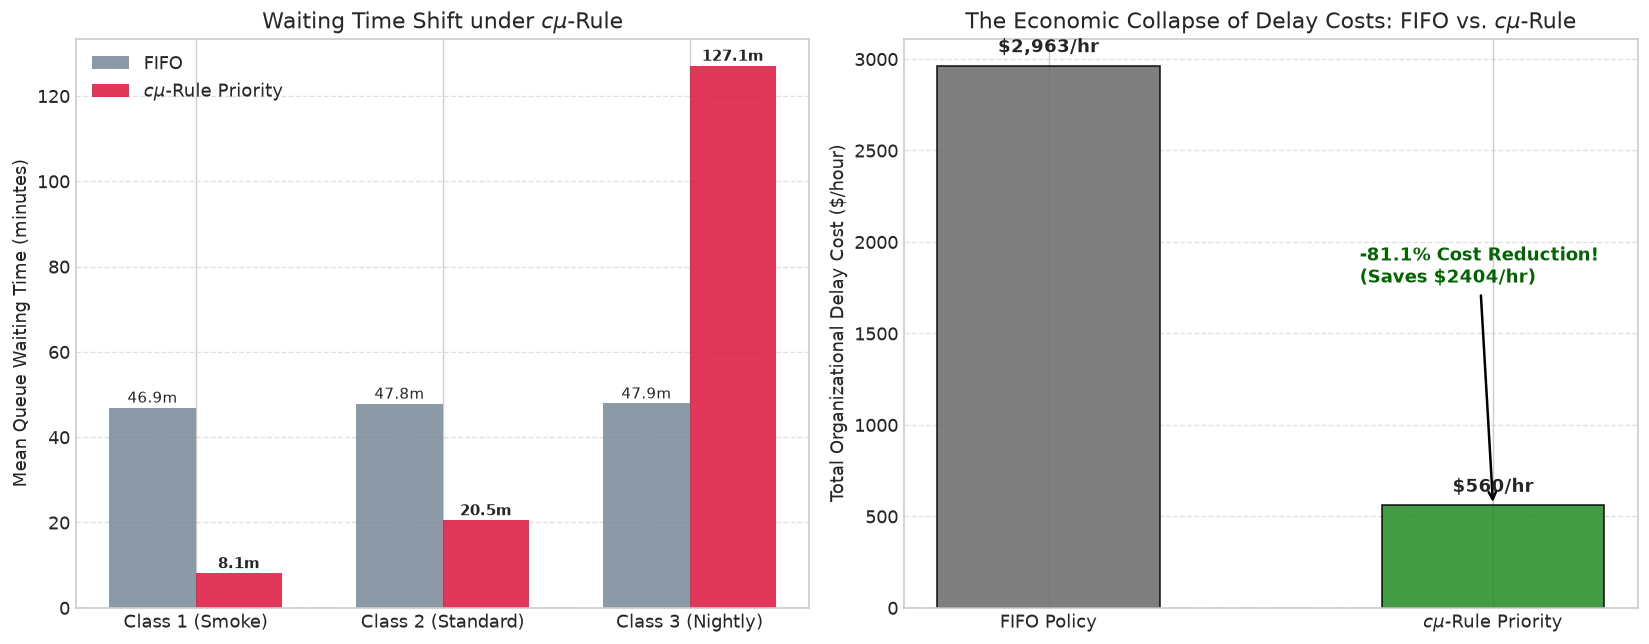

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Waiting Time by Class (FIFO vs c*mu Priority)
class_labels = [c["name"] for c in classes]
x = np.arange(len(classes))
width = 0.35

fifo_waits = [sim_fifo[i]["mean_wq"] for i in range(len(classes))]
prio_waits = [sim_prio[i]["mean_wq"] for i in range(len(classes))]

rects1 = ax1.bar(x - width/2, fifo_waits, width, label='FIFO', color='slategray', alpha=0.8)
rects2 = ax1.bar(x + width/2, prio_waits, width, label=r'$c\mu$-Rule Priority', color='crimson', alpha=0.85)

ax1.set_ylabel('Mean Queue Waiting Time (minutes)')
ax1.set_title('Waiting Time Shift under $c\mu$-Rule')
ax1.set_xticks(x)
ax1.set_xticklabels(class_labels)
ax1.legend()
ax1.grid(True, axis='y', linestyle='--', alpha=0.6)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}m', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}m', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9, fontweight='bold')

# Subplot 2: Total Hourly Delay Cost Comparison
fifo_costs = [classes[i]["cost"] * (classes[i]["lambda"]) * (sim_fifo[i]["mean_wq"] / 60.0) for i in range(len(classes))]
prio_costs = [classes[i]["cost"] * (classes[i]["lambda"]) * (sim_prio[i]["mean_wq"] / 60.0) for i in range(len(classes))]

total_fifo_cost = sum(fifo_costs)
total_prio_cost = sum(prio_costs)

categories = ['FIFO Policy', r'$c\mu$-Rule Priority']
costs = [total_fifo_cost, total_prio_cost]

bars = ax2.bar(categories, costs, color=['dimgray', 'forestgreen'], width=0.5, edgecolor='black', alpha=0.85)
ax2.set_ylabel('Total Organizational Delay Cost ($/hour)')
ax2.set_title(r'The Economic Collapse of Delay Costs: FIFO vs. $c\mu$-Rule')
ax2.grid(True, axis='y', linestyle='--', alpha=0.6)

savings_pct = 100.0 * (1.0 - total_prio_cost / total_fifo_cost)
ax2.annotate(f"-{savings_pct:.1f}% Cost Reduction!\n(Saves ${(total_fifo_cost - total_prio_cost):.0f}/hr)",
             xy=(1, total_prio_cost), xytext=(0.7, total_fifo_cost * 0.6),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             fontsize=11, fontweight='bold', color='darkgreen')

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 50, f"${yval:,.0f}/hr", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()
